# Naive Bayes spam filter

Spam filter written from scratch with numpy and pandas, trained on the Enron-Spam dataset.

## Setup

In [1]:
import re
import zipfile
import urllib.request
from collections import Counter
from pathlib import Path

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords

## Data

In [2]:
csv_path = Path("enron_spam_data.csv")

if not csv_path.exists():
    url = "https://raw.githubusercontent.com/MWiechmann/enron_spam_data/master/enron_spam_data.zip"
    urllib.request.urlretrieve(url, "enron_spam_data.zip")
    zipfile.ZipFile("enron_spam_data.zip").extractall()
    Path("enron_spam_data.zip").unlink()

emails = pd.read_csv(csv_path)
emails["text"] = emails["Subject"].fillna("") + " " + emails["Message"].fillna("")
emails["spam"] = (emails["Spam/Ham"] == "spam").astype(int)
emails = emails[["text", "spam"]]

spam_texts = emails.loc[emails["spam"] == 1, "text"]
if spam_texts.nunique() < len(spam_texts) / 2:
    raise ValueError("most spam emails in this file have identical text, the csv is corrupted")

Exact duplicates are removed so the same email cannot appear in both train and test.

In [3]:
rows_before = len(emails)
emails = emails.drop_duplicates(subset="text")
emails = emails.sample(frac=1, random_state=42, ignore_index=True)

class_counts = emails["spam"].value_counts().rename({0: "ham", 1: "spam"})
print(f"{rows_before} emails, {rows_before - len(emails)} duplicates removed")
pd.DataFrame({"emails": class_counts, "share": (class_counts / len(emails)).round(3)})

33716 emails, 3222 duplicates removed


,emails,share
spam,,
ham,15910,0.522
spam,14584,0.478


## Text cleaning

In [4]:
nltk.download("stopwords", quiet=True)
STOPWORDS = set(stopwords.words("english"))


def tokenize(text):
    words = re.findall(r"[a-z0-9]+", text.lower())
    return [word for word in words if len(word) > 1 and word not in STOPWORDS]


emails["tokens"] = emails["text"].apply(tokenize)

## Train / test split

In [5]:
split_index = int(len(emails) * 0.8)
train_emails = emails.iloc[:split_index]
test_emails = emails.iloc[split_index:]

print(f"train: {len(train_emails)} emails, test: {len(test_emails)} emails")

train: 24395 emails, test: 6099 emails


## Model

In [6]:
class SpamFilter:
    def fit(self, docs, labels):
        spam_counts, ham_counts = Counter(), Counter()
        for words, label in zip(docs, labels):
            (spam_counts if label == 1 else ham_counts).update(set(words))

        n_spam = int(np.sum(labels == 1))
        n_ham = len(labels) - n_spam

        word_table = pd.DataFrame({"spam": pd.Series(spam_counts), "ham": pd.Series(ham_counts)}).fillna(0)
        spam_rate = (word_table["spam"] + 1) / (n_spam + 2)
        ham_rate = (word_table["ham"] + 1) / (n_ham + 2)
        word_table["log_odds"] = np.log(spam_rate) - np.log(ham_rate)

        self.word_table = word_table
        self.log_odds = word_table["log_odds"].to_dict()
        self.prior = np.log(n_spam / n_ham)
        return self

    def score(self, docs):
        return np.array([self.prior + sum(self.log_odds.get(word, 0.0) for word in words) for words in docs])

    def predict(self, docs):
        return (self.score(docs) > 0).astype(int)

    def predict_proba(self, docs):
        scores = np.clip(self.score(docs), -500, 500)
        return 1 / (1 + np.exp(-scores))

## Evaluation

In [7]:
def confusion_table(y_true, y_pred):
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    return pd.DataFrame(
        [[tn, fp], [fn, tp]],
        index=["actual ham", "actual spam"],
        columns=["predicted ham", "predicted spam"],
    )


def evaluate(y_true, y_pred):
    matrix = confusion_table(y_true, y_pred).to_numpy()
    tn, fp, fn, tp = matrix.ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "accuracy": round(float((tp + tn) / matrix.sum()), 4),
        "precision": round(float(precision), 4),
        "recall": round(float(recall), 4),
        "f1": round(float(f1), 4),
        "false_positives": int(fp),
        "false_negatives": int(fn),
    }

In [8]:
spam_filter = SpamFilter().fit(train_emails["tokens"], train_emails["spam"].to_numpy())

test_labels = test_emails["spam"].to_numpy()
test_predictions = spam_filter.predict(test_emails["tokens"])

confusion_table(test_labels, test_predictions)

,predicted ham,predicted spam
actual ham,3111,29
actual spam,61,2898


In [9]:
pd.Series(evaluate(test_labels, test_predictions), dtype=object)

accuracy           0.9852
precision          0.9901
recall             0.9794
f1                 0.9847
false_positives        29
false_negatives        61
dtype: object

## Most informative words

Words that appear in at least 100 emails, ranked by log-odds.

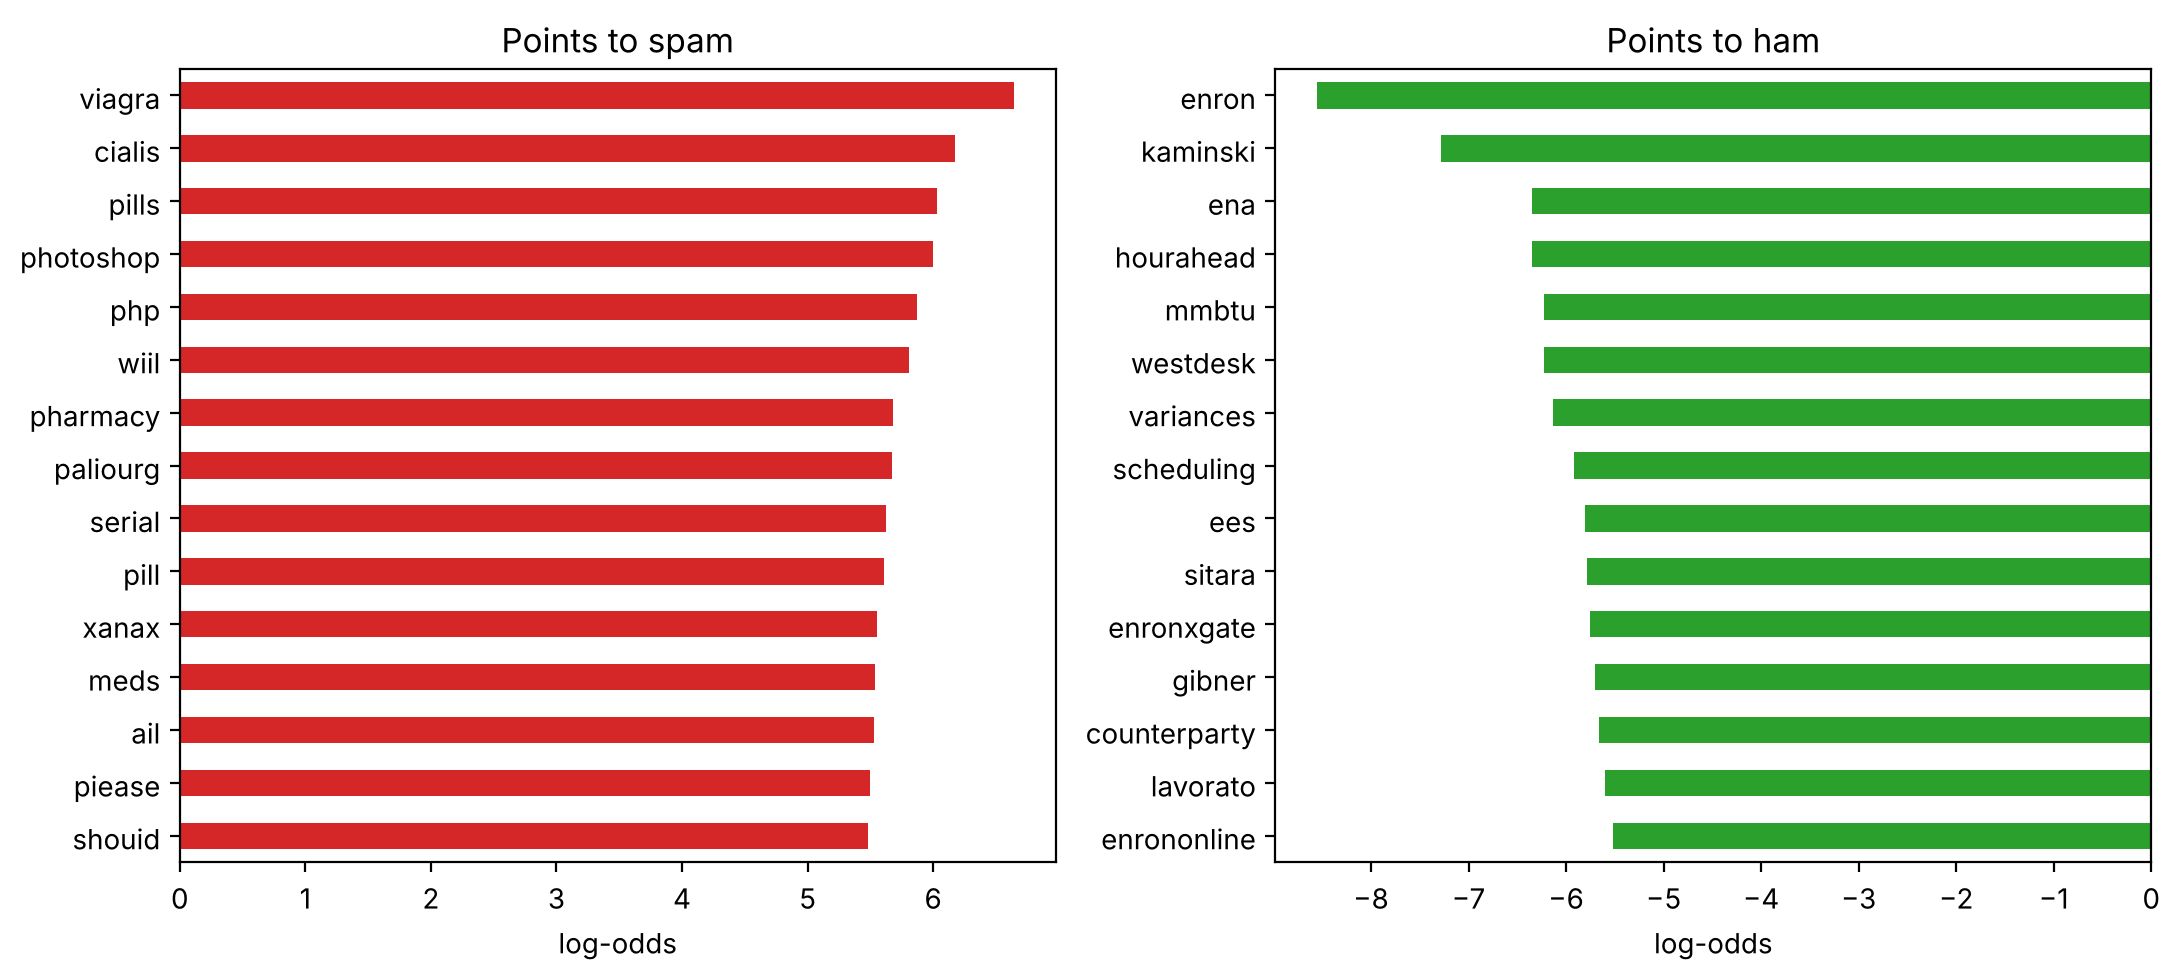

In [10]:
common_words = spam_filter.word_table[(spam_filter.word_table["spam"] + spam_filter.word_table["ham"]) >= 100]
top_spam_words = common_words["log_odds"].nlargest(15)
top_ham_words = common_words["log_odds"].nsmallest(15)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
top_spam_words[::-1].plot.barh(ax=axes[0], color="tab:red", title="Points to spam")
top_ham_words[::-1].plot.barh(ax=axes[1], color="tab:green", title="Points to ham")
for ax in axes:
    ax.set_xlabel("log-odds")
plt.tight_layout()
plt.show()

## Example predictions

In [11]:
def classify_text(text):
    probability = spam_filter.predict_proba([tokenize(text)])[0]
    label = "spam" if probability > 0.5 else "ham"
    print(f"{label:<4} ({probability:6.1%} spam)  {text}")


classify_text("Click here to win a free lottery prize, claim your money now")
classify_text("Hi John, can we move tomorrow's meeting to 3pm? Please bring the report")
classify_text("Cheap meds online, no prescription needed, order today and save big")
classify_text("The schedule for next week's project review is attached")

spam (100.0% spam)  Click here to win a free lottery prize, claim your money now
ham  (  0.0% spam)  Hi John, can we move tomorrow's meeting to 3pm? Please bring the report
spam (100.0% spam)  Cheap meds online, no prescription needed, order today and save big
ham  (  0.0% spam)  The schedule for next week's project review is attached
